# 20. 결합 사양 정리 — 개수 연동 예산, 두 평가 방식 비교, 파생 5종 구성요소
결합 = raw PVC(제공 4 + 파생 3, 일별 개수 학습, 10시드 평균)와 D4(파생 5종 날짜 안 이탈 크기 합, 학습 없음)의 날짜 안 순위 평균.
평가 1 = 날짜 하나 빼기(Stellantis N.V. 20일, 불량 79). 평가 2 = 시간순(2022~2023 학습 → 2024 5일, 불량 51).
개수 연동 예산의 추정 불량 수는 고정 불량률(학습 날짜 평균 불량률 × 그날 타점 수)로 둔다(반복 4에서 집계 로지스틱과 동등).

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings
from sklearn.metrics import roc_auc_score
import br
from br import spec as S, budget as B, plot as P
from wl.metrics import inclusion_prob
from wl import data as wldata
warnings.filterwarnings("ignore"); P.setup(); pd.set_option("display.width", 220)
X, day, cnt, y, _ = S.load_polito(); Xd, *_ = S.load_polito("derived5_absz")
body = wldata.load_polito().body.values
RAW = pd.read_pickle(br.RES / "same_model_scores.pkl")
def mcol(model, col):
    return np.mean([g.sort_values("row")[col].values for _, g in RAW[(RAW.data == "polito") & (RAW.model == model)].groupby("seed")], 0)

def setup(mask, raw_s, d4_s, rate):
    yt, dt, bt = y[mask], day[mask], body[mask]
    rk = lambda s: pd.Series(s).groupby(dt).rank(pct=True).values
    ud, gi = np.unique(dt, return_inverse=True); n = np.bincount(gi)
    est = rate * n if np.isscalar(rate) else rate
    return dict(y=yt, gi=gi, n=n, pos=np.bincount(gi, weights=yt), body=bt, est=est,
                S={"raw PVC": raw_s, "D4 규칙": d4_s, "결합": (rk(raw_s) + rk(d4_s)) / 2})
# 평가 1: LODO
lodo_rate = np.bincount(np.unique(day, return_inverse=True)[1], weights=mcol("고정 불량률", "prob"))
E1 = setup(np.ones(len(y), bool), mcol("PVC MLP", "score"), Xd.sum(axis=1).values, lodo_rate)
# 평가 2: 시간순
TR = np.array([d_ < "2024" for d_ in day]); TE = np.array([d_ >= "2024-02-01" for d_ in day])
ub, bag = np.unique(day[TR], return_inverse=True)
raw_t = np.mean([S.fit_score("PVC MLP", X, bag, cnt.loc[ub].values.astype(int), TR, TE, s)[0] for s in range(10)], 0)
E2 = setup(TE, raw_t, Xd.sum(axis=1).values[TE], y[TR].mean())
EV = {"날짜 하나 빼기": E1, "시간순(2024 시험)": E2}

## 1. 개수 연동 예산 (추정 불량 수 × m) — 결합 순위

In [2]:
rng = np.random.default_rng(11)
rows = []
for ev, E in EV.items():
    ubt = np.unique(E["body"]); Wb = np.stack([np.bincount(d_, minlength=len(ubt)) for d_ in rng.integers(0, len(ubt), (5000, len(ubt)))])[:, np.searchsorted(ubt, E["body"])]
    for m in (2.5, 5, 10):
        k = np.minimum(np.ceil(m * E["est"] - 1e-9), E["n"]).astype(float); pr = (k / E["n"])[E["gi"]]
        for nm in ["raw PVC", "결합"]:
            p_ = inclusion_prob(E["S"][nm], k, E["gi"])
            d_ = (Wb @ ((p_ - pr) * E["y"])) / (Wb @ E["y"])
            rows.append({"평가": ev, "배수": m, "모델": nm, "검사 수": int(k.sum()), "검사 비율": round(k.sum() / len(E["y"]), 3),
                         "포착": round((p_ * E["y"]).sum(), 1), "같은 수 무작위": round((pr * E["y"]).sum(), 1),
                         "무작위 대비 [95%]": f"{d_.mean():+.3f} [{np.quantile(d_,.025):+.3f}, {np.quantile(d_,.975):+.3f}]"})
cb = pd.DataFrame(rows); cb.to_csv(br.RES / "combined_count_budget.csv", index=False, encoding="utf-8-sig"); display(cb)

,평가,배수,모델,검사 수,검사 비율,포착,같은 수 무작위,무작위 대비 [95%]
0,날짜 하나 빼기,2.5,raw PVC,210,0.106,21.0,8.4,"+0.155 [+0.047, +0.240]"
1,날짜 하나 빼기,2.5,결합,210,0.106,23.0,8.4,"+0.180 [+0.063, +0.278]"
2,날짜 하나 빼기,5.0,raw PVC,408,0.206,37.0,15.5,"+0.267 [+0.132, +0.385]"
3,날짜 하나 빼기,5.0,결합,408,0.206,38.0,15.5,"+0.282 [+0.154, +0.395]"
4,날짜 하나 빼기,10.0,raw PVC,807,0.408,54.0,30.9,"+0.287 [+0.147, +0.392]"
5,날짜 하나 빼기,10.0,결합,807,0.408,52.0,30.9,"+0.262 [+0.133, +0.364]"
6,시간순(2024 시험),2.5,raw PVC,59,0.063,5.0,3.9,"+0.020 [-0.040, +0.078]"
7,시간순(2024 시험),2.5,결합,59,0.063,11.0,3.9,"+0.134 [+0.010, +0.236]"
8,시간순(2024 시험),5.0,raw PVC,115,0.124,13.0,6.7,"+0.118 [-0.010, +0.216]"
9,시간순(2024 시험),5.0,결합,115,0.124,17.0,6.7,"+0.196 [+0.060, +0.323]"


## 2. 파생 5종 구성요소별 기여 (설명용, 사양 변경 없음)

In [3]:
groups = {"수준(입열량·동저항·I/F)": ["heat", "dynres", "i_over_f"], "이동 중앙값 편차": [c for c in Xd if c.startswith("dev_")],
          "직전 변화량": [c for c in Xd if c.startswith("dl_")], "전체 9개(D4)": list(Xd.columns)}
rows = []
for ev, mask in [("날짜 하나 빼기", np.ones(len(y), bool)), ("시간순(2024 시험)", TE)]:
    E = EV[ev]
    for g, cols in groups.items():
        s_ = Xd.loc[mask, cols].sum(axis=1).values
        k = np.ceil(.1 * E["n"] - 1e-9)
        rows.append({"평가": ev, "구성요소": g, "AUROC": round(roc_auc_score(E["y"], s_), 3),
                     "10% 포착": round((inclusion_prob(s_, k, E["gi"]) * E["y"]).sum(), 1), "무작위": round((k / E["n"] * E["pos"]).sum(), 1)})
comp = pd.DataFrame(rows); comp.to_csv(br.RES / "d4_components.csv", index=False, encoding="utf-8-sig"); display(comp)

,평가,구성요소,AUROC,10% 포착,무작위
0,날짜 하나 빼기,수준(입열량·동저항·I/F),0.654,20.0,8.6
1,날짜 하나 빼기,이동 중앙값 편차,0.630,15.0,8.6
2,날짜 하나 빼기,직전 변화량,0.606,9.0,8.6
3,날짜 하나 빼기,전체 9개(D4),0.656,17.0,8.6
4,시간순(2024 시험),수준(입열량·동저항·I/F),0.710,15.0,5.7
5,시간순(2024 시험),이동 중앙값 편차,0.657,10.0,5.7
6,시간순(2024 시험),직전 변화량,0.627,8.0,5.7
7,시간순(2024 시험),전체 9개(D4),0.709,14.0,5.7


## 3. 보고서용 그림 — 두 평가 방식에서 raw · D4 · 결합

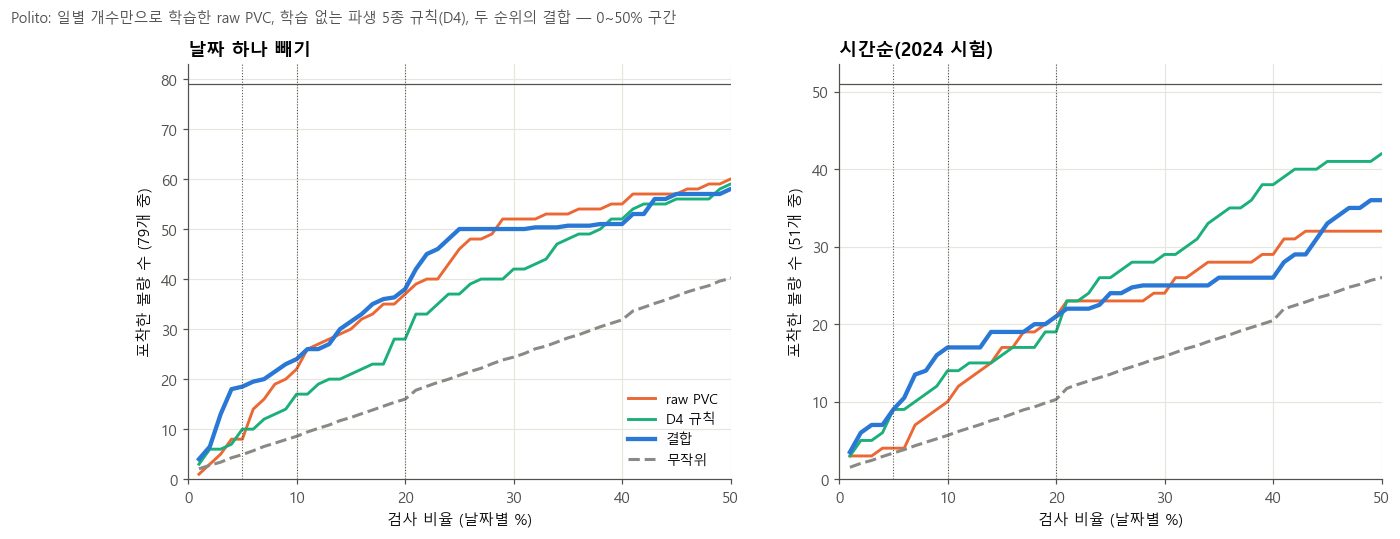

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.9))
bb = B.BUDGETS
for ax, (ev, E) in zip(axes, EV.items()):
    for nm, col, lw in [("raw PVC", P.PAL[1], 1.9), ("D4 규칙", P.PAL[2], 1.9), ("결합", P.PAL[0], 2.8)]:
        ax.plot(bb * 100, [(inclusion_prob(E["S"][nm], np.ceil(b * E["n"] - 1e-9), E["gi"]) * E["y"]).sum() for b in bb], color=col, lw=lw, label=nm)
    ax.plot(bb * 100, [(np.ceil(b * E["n"] - 1e-9) / E["n"] * E["pos"]).sum() for b in bb], "--", color=P.GRAY, label="무작위")
    ax.axhline(E["y"].sum(), color=P.INK2, lw=.8)
    for b in (5, 10, 20): ax.axvline(b, color=P.INK2, lw=.7, ls=":")
    ax.set_xlim(0, 50); ax.set_ylim(0, E["y"].sum() * 1.05)
    ax.set_xlabel("검사 비율 (날짜별 %)"); ax.set_ylabel(f"포착한 불량 수 ({int(E['y'].sum())}개 중)")
    ax.set_title(f"{ev}", loc="left", fontweight="bold")
axes[0].legend(fontsize=9, loc="lower right")
fig.suptitle("Stellantis N.V.: 일별 개수만으로 학습한 raw PVC, 학습 없는 파생 5종 규칙(D4), 두 순위의 결합 — 0~50% 구간", x=0.01, ha="left", color=P.INK2, fontsize=9.5)
P.save(fig, "18_combined_two_evals"); plt.show()